# Supplementary Fig. 4a: distributions of the firing rates of the sorted single-units, by spike sorter and layer

**author**: laquitainesteeve@gmail.com

**purpose**: reproduce panel a of Supplementary Fig. 4: distribution of the firing rates of the sorted single-units of the Marques-Smith recording (M, grey), the biophysical models of the spontaneous (NS, red) and evoked (E, orange) regimes and the synthetic model (S, blue; layer 5 only) for each spike sorter (columns), for the whole column and for each layer (rows), with lognormal fits (lines). Source data and svg are saved in figures/8_source_data/supp_fig4a/.

**method (as in fig4a.ipynb, repeated for each sorter)**: sortings of the first 10 minutes of each recording; units in cortex; single-units only (Kilosort's 'good' label), except for Kilosort which does not label units; histogram of the log10 firing rates in 30 bins between 10^-3 and 10^3 spikes/s and lognormal fit.

**data**: the sortings are in `dataset/01_intermediate/sorting/`, downloaded with `0_download_sortings.ipynb` (DANDI 001250) or spike sorted with `src/pipes/sorting/`.

In [1]:
%load_ext autoreload
%autoreload 2
from matplotlib import pyplot as plt
import numpy as np
import os
import warnings
import pandas as pd
import spikeinterface as si

warnings.simplefilter(action='ignore', category=FutureWarning)
warnings.filterwarnings("ignore")

# SET PROJECT PATH

PROJ_PATH = "/home/steeve/steeve/epfl/code/spikebias"
os.chdir(PROJ_PATH)
from src.nodes.utils import get_config, savefig
from src.nodes.validation import firing_rate as fr
from src.nodes.validation.npx_probe import firing_rate as fr_npx

# SETUP EXPERIMENTS

# sorting paths (10 minutes): dataset/01_intermediate/sorting/<experiment>/<sorting folder>
SORTING_ROOT = "dataset/01_intermediate/sorting"
EXPERIMENT_FOLDERS = {"M": "marques", "NS": "npx_spont", "E": "npx_evoked_40khz", "S": "buccino"}
SORTERS = {                    # title: (sorting folder, only single units?)
    "Kilosort4": ("SortingKS4_10m", True),
    "Kilosort3": ("SortingKS3_10m", True),
    "Kilosort2.5": ("SortingKS2_5_10m", True),
    "Kilosort2": ("SortingKS2_10m", True),
    "Kilosort": ("SortingKS_10m", False),     # Kilosort does not classify single and multi-units: all units are reported
}

# Kilosort4: the sortings of Fig. 4 (M: first 10 minutes of the sorting of the whole recording; NS: Tesla V100 sorting); other sorters: sortings of the first 10 minutes of each recording
PATH_OVERRIDES = {"Kilosort4": {"M": "marques/SortingKS4_10m_rtx5090", "NS": "npx_spont_v100/SortingKS4_10m", "E": "npx_evoked_40khz/SortingKS4_10m"}}

# PARAMETERS
layers = ["L1", "L2/3", "L4", "L5", "L6"]

# SETUP PLOT 

# set lognormal plot parameters
log_x_min = -3.0
log_x_max = 3.0
nbins = 30

# IF you don't want to use the feature, set the value to 1E100
# t_dec = 3600 # seconds until experimenter decides a cell is silent
t_dec = 1^100 # seconds until experimenter decides a cell is silent

cl = dict()
cl["COLOR_NV"] = [0.6, 0.6, 0.6]
cl["COLOR_NS"] = [0.9, 0.14, 0.15]
cl["COLOR_NB"] = [0.22, 0.5, 0.72] # blue
cl["COLOR_NE"] = [1, 0.49, 0] # orange
cl["COLOR_HV"] = "k" # black
cl["COLOR_HS"] = np.array([26, 152, 80]) / 255 # green

# axes
plt.rcParams["font.family"] = "DejaVu Sans"   # the paper's figure was drawn without Arial (matplotlib default font)
plt.rcParams["font.size"] = 6  # 5-7 with Nature neuroscience as reference
plt.rcParams["lines.linewidth"] = 0.5 # typically between 0.5 and 1
plt.rcParams["axes.linewidth"] = 0.5 #1
plt.rcParams["axes.spines.top"] = False
plt.rcParams["xtick.major.width"] = 0.5 #0.8 #* 1.3
plt.rcParams["xtick.minor.width"] = 0.5 #0.8 #* 1.3
plt.rcParams["ytick.major.width"] = 0.5 #0.8 #* 1.3
plt.rcParams["ytick.minor.width"] = 0.5 #0.8 #* 1.3
plt.rcParams["xtick.major.size"] = 3.5 * 1.1
plt.rcParams["xtick.minor.size"] = 2 * 1.1
plt.rcParams["ytick.major.size"] = 3.5 * 1.1
plt.rcParams["ytick.minor.size"] = 2 * 1.1

# legend
legend_cfg = {"frameon": False, "handletextpad": 0.5}
tight_layout_cfg = {"pad": 0.001}
LG_FRAMEON = False              # no legend frame

savefig_cfg = {"transparent":True, "dpi": 400}

In [2]:
# Nature figure guidelines for every saved figure: Arial, 5-7 pt, editable text, images of at least 300 dpi, a .pdf next to each .svg
import os, sys
sys.path.insert(0, os.getcwd())     # the repository (the notebook moved there above)
from src.nodes import figure_style
figure_style.apply()

## Get the metadata of the sorted units

In [3]:
%%time

LAYER_NAMES = ["L1", "L2/3", "L4", "L5", "L6"]
DURATION_SEC = 600              # duration of the sortings
df_units = {}       # {sorter title: {experiment: units}}
for title, (folder, single_unit) in SORTERS.items():
    df = {}
    for exp, exp_folder in EXPERIMENT_FOLDERS.items():
        path = f"{SORTING_ROOT}/" + PATH_OVERRIDES.get(title, {}).get(exp, f"{exp_folder}/{folder}")
        d = fr.get_synth_unit_meta(path) if exp == "S" else fr.get_sorted_unit_meta(path)
        d = fr.fix_firing_rates(d, si.load_extractor(path), path, DURATION_SEC)
        if exp != "S":
            d = d[np.isin(d["layer"], LAYER_NAMES)]           # units in cortex
        if single_unit:
            d = d[d["kslabel"] == "good"]
        df[exp] = d
    df_units[title] = df
    print(f"{title:12s} unit counts:", {e: d.shape[0] for e, d in df.items()})

Kilosort4    unit counts: {'M': 106, 'NS': 257, 'E': 273, 'S': 377}
Kilosort3    unit counts: {'M': 111, 'NS': 233, 'E': 333, 'S': 349}


Kilosort2.5  unit counts: {'M': 186, 'NS': 578, 'E': 196, 'S': 413}
Kilosort2    unit counts: {'M': 944, 'NS': 1187, 'E': 205, 'S': 1512}
2026-11-05 14:03:44,969 - root - utils.py - get_kslabel - INFO - No KSLabel property in SortingExtractor


2026-11-05 14:03:44,969 - root - utils.py - get_amplitude - INFO - No Amplitude property in SortingExtractor


2026-11-05 14:03:45,007 - root - utils.py - get_kslabel - INFO - No KSLabel property in SortingExtractor


2026-11-05 14:03:45,007 - root - utils.py - get_amplitude - INFO - No Amplitude property in SortingExtractor


2026-11-05 14:03:45,043 - root - utils.py - get_kslabel - INFO - No KSLabel property in SortingExtractor


2026-11-05 14:03:45,043 - root - utils.py - get_amplitude - INFO - No Amplitude property in SortingExtractor


2026-11-05 14:03:45,069 - root - utils.py - get_kslabel - INFO - No KSLabel property in SortingExtractor


2026-11-05 14:03:45,069 - root - utils.py - get_amplitude - INFO - No Amplitude property in SortingExtractor


Kilosort     unit counts: {'M': 1457, 'NS': 1806, 'E': 2208, 'S': 1254}
CPU times: user 613 ms, sys: 23 ms, total: 636 ms
Wall time: 635 ms


## Plot, same as the paper's panel a

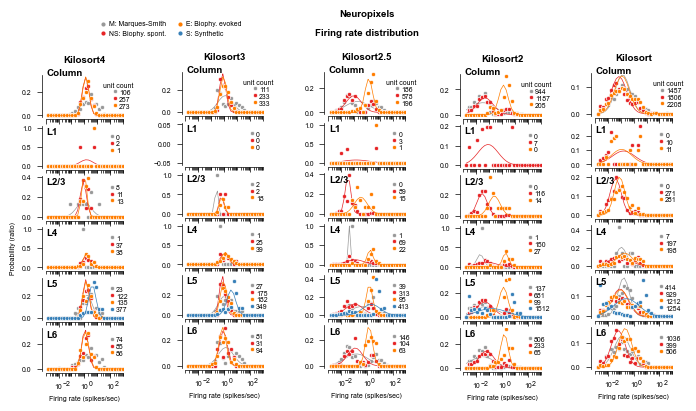

In [4]:
from src.nodes.validation import supp_fig4_layout as lay


def make_axes():
    """5 x 6 axes at the positions of the paper's panel a: the whole column and the five layers (rows) for each sorter (columns)"""
    fig = lay.new_figure(lay.A_CANVAS)
    return fig, lay.axes_a(fig)


def annotate_figure(fig, axes):
    """titles and legend of the paper's panel a, then text sizes (5 pt, 7 pt for the titles)"""
    for c, title in enumerate(SORTERS):
        axes[c][0].set_title(title, fontsize=7, fontweight="bold", pad=9)
    lay.text_pt(fig, 265.8, 6.0, "Neuropixels", fontsize=7, fontweight="bold")
    lay.text_pt(fig, 265.8, 19.5, "Firing rate distribution", fontsize=7, fontweight="bold")
    labels = [("M: Marques-Smith", cl["COLOR_NV"], 76.0, 13.0), ("NS: Biophy. spont.", cl["COLOR_NS"], 76.0, 20.0), ("E: Biophy. evoked", cl["COLOR_NE"], 131.0, 13.0), ("S: Synthetic", cl["COLOR_NB"], 131.0, 20.0)]
    for label, color, x, y in labels:
        x0, y0, w, h = fig._origin
        fig.add_artist(plt.Line2D([(x - x0) / w], [1 - (y - y0) / h], marker="o", color=color, markersize=3, linestyle="none", markeredgewidth=0))
        t = lay.text_pt(fig, x + 4.5, y, label, ha="left")
    # tick labels 10^-2, 10^0, 10^2 of the last row: "10" and its exponent are two texts of 5 pt (a mathtext exponent would be smaller than 5 pt)
    for c in range(len(SORTERS)):
        ax = axes[c][5]
        ax.set_xticks([0.01, 1, 100])
        ax.set_xticklabels(["10", "10", "10"])
        for x, exponent in zip([0.01, 1, 100], ["\u22122", "0", "2"]):     # EXPONENT
            ax.annotate(exponent, xy=(x, 0), xycoords=("data", "axes fraction"), xytext=(3.0, -9.3), textcoords="offset points", ha="left", va="center", fontsize=5)
    lay.set_text_sizes(fig, titles=list(SORTERS) + ["Neuropixels", "Firing rate distribution"])


fig, axes = make_axes()
df_hist = []
for c, (title, df) in enumerate(df_units.items()):
    _, d = fr_npx.plot_fr_by_layer(axes[c], df["M"], df["NS"], df["E"], df["S"], layers, log_x_min, log_x_max, nbins, t_dec, cl)
    df_hist.append(d.assign(sorter=title))
    if c > 0:       # y label only once
        for a in axes[c]:
            a.set_ylabel("")
df_hist = pd.concat(df_hist, ignore_index=True)
annotate_figure(fig, axes)

## Save the figure and the source data

In [5]:
os.makedirs("figures/8_source_data/supp_fig4a", exist_ok=True)
fig.savefig("figures/8_source_data/supp_fig4a/supp_fig4a.svg", bbox_inches="tight", **savefig_cfg)
df_hist.to_excel("figures/8_source_data/supp_fig4a/supp_fig4a.xlsx", index=False)
display(df_hist.drop_duplicates(["sorter", "layer", "experiment"])[["sorter", "layer", "experiment", "n"]].pivot_table(index=["sorter", "layer"], columns="experiment", values="n").loc[list(SORTERS)])

2026-11-05 14:03:53,155 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - maxp pruned


2026-11-05 14:03:53,156 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - LTSH dropped


2026-11-05 14:03:53,156 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - cmap pruned


2026-11-05 14:03:53,159 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - kern pruned


2026-11-05 14:03:53,159 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - post pruned


2026-11-05 14:03:53,159 - fontTools.subset - __init__.py - _prune_pre_subset - INFO - PCLT dropped


... (93 outputs left out)

2026-11-05 14:03:53,189 - fontTools.subset - __init__.py - _prune_post_subset - INFO - GDEF pruned to empty; dropped


2026-11-05 14:03:53,189 - fontTools.subset - __init__.py - _prune_post_subset - INFO - GSUB pruned


2026-11-05 14:03:53,191 - fontTools.subset - __init__.py - _prune_post_subset - INFO - name pruned


experiment               E       M      NS       S
sorter      layer                                 
Kilosort4   Column   273.0   106.0   257.0     NaN
            L1         1.0     0.0     2.0     NaN
            L2/3      13.0     8.0    11.0     NaN
            L4        38.0     1.0    37.0     NaN
            L5       135.0    23.0   122.0   377.0
            L6        86.0    74.0    85.0     NaN
Kilosort3   Column   333.0   111.0   233.0     NaN
            L1         0.0     0.0     0.0     NaN
            L2/3      18.0     2.0     2.0     NaN
            L4        39.0     1.0    25.0     NaN
            L5       182.0    27.0   175.0   349.0
            L6        94.0    81.0    31.0     NaN
Kilosort2.5 Column   196.0   186.0   578.0     NaN
            L1         1.0     0.0     3.0     NaN
            L2/3      15.0     0.0    89.0     NaN
            L4        22.0     1.0    69.0     NaN
            L5        95.0    39.0   313.0   413.0
            L6        63.0   146.0   104.0     NaN
Kilosort2   Column   205.0   944.0  1187.0     NaN
            L1         0.0     0.0     7.0     NaN
            L2/3      14.0     0.0   116.0     NaN
            L4        27.0     1.0   150.0     NaN
            L5        99.0   137.0   681.0  1512.0
            L6        65.0   806.0   233.0     NaN
Kilosort    Column  2208.0  1457.0  1806.0     NaN
            L1        11.0     0.0    10.0     NaN
            L2/3     281.0     0.0   271.0     NaN
            L4       198.0     7.0   197.0     NaN
            L5      1212.0   414.0   929.0  1254.0
            L6       506.0  1036.0   399.0     NaN

## Check: replot from the saved source data

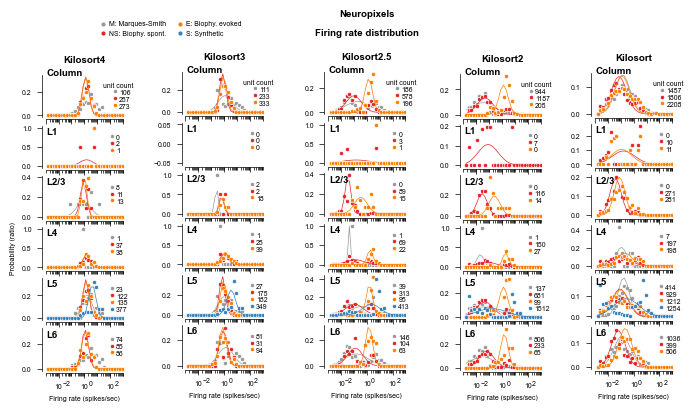

In [6]:
df_hist_loaded = pd.read_excel("figures/8_source_data/supp_fig4a/supp_fig4a.xlsx")
fig, axes = make_axes()
for c, title in enumerate(SORTERS):
    fr_npx.plot_fr_by_layer_from_df(axes[c], df_hist_loaded[df_hist_loaded["sorter"] == title], layers, cl)
    if c > 0:
        for a in axes[c]:
            a.set_ylabel("")
annotate_figure(fig, axes)